In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [ ]:

from pathlib import Path
import torchvision
from torchvision import transforms

# Parent folder containing "cifar-10-batches-py"
data_root = Path.home() / "Desktop" / "Ai project" / "Viki DL"

transform = transforms.Compose([
    transforms.ToTensor()
])

# Verify that the local dataset exists
dataset_folder = data_root / "cifar-10-batches-py"

assert (dataset_folder / "data_batch_1").exists(), (
    f"CIFAR-10 files not found in: {dataset_folder}"
)

# Load training dataset from local files
train_dataset = torchvision.datasets.CIFAR10(
    root=str(data_root),
    train=True,
    download=False,
    transform=transform
)

# Load test dataset from local files
test_dataset = torchvision.datasets.CIFAR10(
    root=str(data_root),
    train=False,
    download=False,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))


Training samples: 50000
Testing samples: 10000


In [ ]:
print("Classes:")
print(train_dataset.classes)

Classes:
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [ ]:
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Class:", train_dataset.classes[label])

Image shape: torch.Size([3, 32, 32])
Label: 6
Class: frog


In [ ]:
batch_size = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

print("Train batches:", len(train_loader))
print("Test batches:", len(test_loader))

Train batches: 391
Test batches: 79


In [ ]:
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Batch image shape: torch.Size([128, 3, 32, 32])
Batch label shape: torch.Size([128])


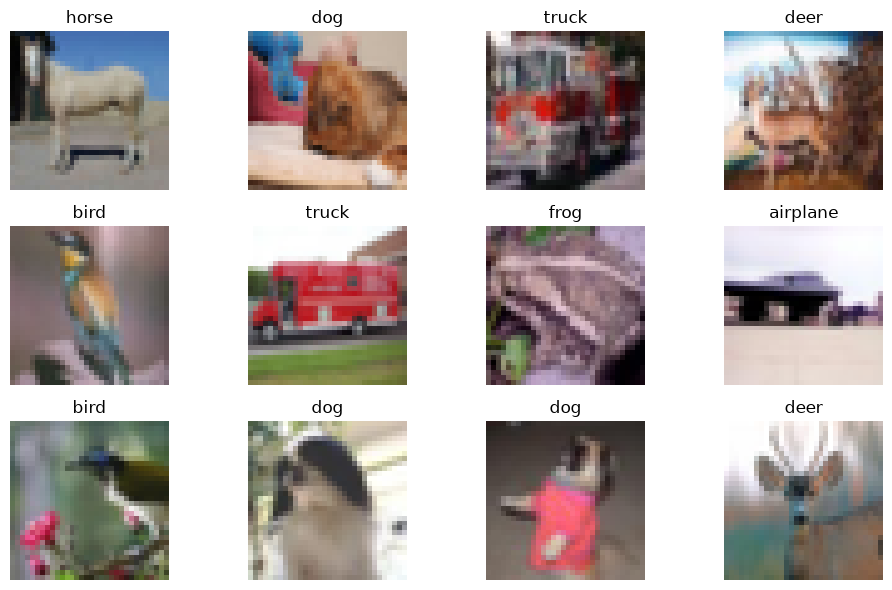

In [ ]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(images[i].permute(1, 2, 0))
    plt.title(train_dataset.classes[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Seed:", SEED)

Seed: 42


## CIFAR-10 ResNet Basic Block

In [ ]:
class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            stride=stride,
            padding=1,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(out_channels)

        self.relu = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(out_channels)

        # Shortcut connection
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):

        identity = self.shortcut(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out += identity
        out = self.relu(out)

        return out

## ResNet model

In [ ]:
class ResNet(nn.Module):

    def __init__(self, num_classes=10):
        super().__init__()

        self.in_channels = 64

        self.conv1 = nn.Conv2d(
            3,
            64,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)

        self.layer1 = self.make_layer(
            64,
            2,
            stride=1
        )

        self.layer2 = self.make_layer(
            128,
            2,
            stride=2
        )

        self.layer3 = self.make_layer(
            256,
            2,
            stride=2
        )

        self.layer4 = self.make_layer(
            512,
            2,
            stride=2
        )

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))

        self.fc = nn.Linear(
            512,
            num_classes
        )

    def make_layer(self, out_channels, blocks, stride):

        layers = []

        layers.append(
            BasicBlock(
                self.in_channels,
                out_channels,
                stride
            )
        )

        self.in_channels = out_channels

        for _ in range(1, blocks):
            layers.append(
                BasicBlock(
                    self.in_channels,
                    out_channels
                )
            )

        return nn.Sequential(*layers)

    def forward(self, x):

        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.avgpool(x)

        x = torch.flatten(x, 1)

        x = self.fc(x)

        return x

## Create Model

In [ ]:
model = ResNet(num_classes=10).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    model.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4
)

scheduler = optim.lr_scheduler.MultiStepLR(
    optimizer,
    milestones=[50, 75],
    gamma=0.1
)

In [ ]:
num_epochs = 100

train_losses = []
train_accuracies = []

test_losses = []
test_accuracies = []

best_test_acc = 0.0
best_epoch = 0

### NO of parameters

In [ ]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 11173962
Trainable parameters: 11173962


### Loss function

In [ ]:
criterion = nn.CrossEntropyLoss()

### Optimizer

In [ ]:
optimizer = optim.SGD(
    model.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4
)

### Learning-rate scheduler

In [ ]:
scheduler = optim.lr_scheduler.MultiStepLR(
    optimizer,
    milestones=[50, 75],
    gamma=0.1
)

### Training FXN

In [ ]:
 def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = outputs.max(1)

        total += labels.size(0)

        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = 100.0 * correct / total

    return epoch_loss, epoch_acc

In [ ]:
def evaluate(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = outputs.max(1)

            total += labels.size(0)

            correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = 100.0 * correct / total

    return epoch_loss, epoch_acc

In [ ]:
import time

start_time = time.time()

for epoch in range(num_epochs):

    epoch_start = time.time()

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    test_loss, test_acc = evaluate(
        model,
        test_loader,
        criterion,
        device
    )

    scheduler.step()

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    test_losses.append(test_loss)
    test_accuracies.append(test_acc)

    if test_acc > best_test_acc:
        best_test_acc = test_acc
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            "baseline_resnet_best.pth"
        )

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch [{epoch+1:03d}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:.2f}% | "
        f"Time: {epoch_time:.1f}s"
    )

total_time = time.time() - start_time

print("\nTraining complete!")
print(f"Best Test Accuracy: {best_test_acc:.2f}%")
print(f"Best Epoch: {best_epoch}")
print(f"Total Training Time: {total_time/60:.2f} minutes")

Epoch [001/100] Train Loss: 1.9380 | Train Acc: 30.71% | Test Loss: 1.5725 | Test Acc: 41.94% | Time: 30.4s
Epoch [002/100] Train Loss: 1.3720 | Train Acc: 49.79% | Test Loss: 1.4773 | Test Acc: 47.50% | Time: 29.4s
Epoch [003/100] Train Loss: 1.0902 | Train Acc: 60.71% | Test Loss: 1.3246 | Test Acc: 55.59% | Time: 29.7s
Epoch [004/100] Train Loss: 0.8907 | Train Acc: 68.22% | Test Loss: 1.1484 | Test Acc: 58.93% | Time: 29.6s
Epoch [005/100] Train Loss: 0.7268 | Train Acc: 74.15% | Test Loss: 1.4988 | Test Acc: 56.03% | Time: 29.3s
Epoch [006/100] Train Loss: 0.5897 | Train Acc: 79.46% | Test Loss: 0.7359 | Test Acc: 75.11% | Time: 29.3s
Epoch [007/100] Train Loss: 0.4996 | Train Acc: 82.74% | Test Loss: 0.6966 | Test Acc: 76.30% | Time: 29.6s
Epoch [008/100] Train Loss: 0.4350 | Train Acc: 84.93% | Test Loss: 0.8108 | Test Acc: 73.81% | Time: 29.2s
Epoch [009/100] Train Loss: 0.3852 | Train Acc: 86.58% | Test Loss: 0.6183 | Test Acc: 79.39% | Time: 29.5s
Epoch [010/100] Train Loss: 

In [ ]:
model.load_state_dict(
    torch.load(
        "baseline_resnet_best.pth",
        map_location=device
    )
)

model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (shortcut): Identity()
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Co

### Final baseline evaluation

In [ ]:
final_loss, final_acc = evaluate(
    model,
    test_loader,
    criterion,
    device
)

print(f"Final Baseline Test Loss: {final_loss:.4f}")
print(f"Final Baseline Test Accuracy: {final_acc:.2f}%")

Final Baseline Test Loss: 0.3986
Final Baseline Test Accuracy: 88.18%


### Training graph — Loss

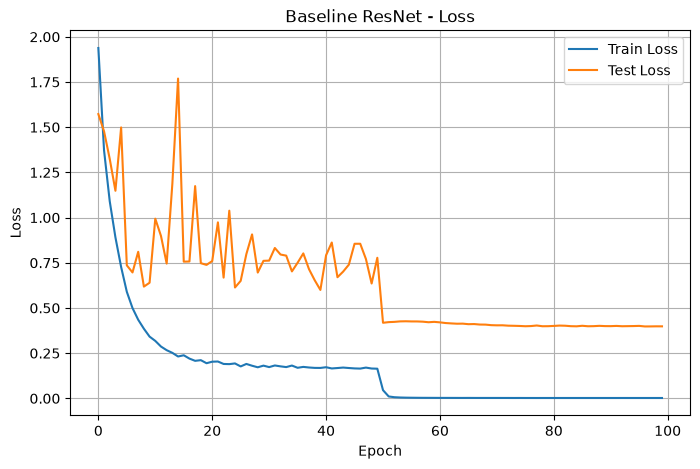

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Train Loss")
plt.plot(test_losses, label="Test Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline ResNet - Loss")
plt.legend()
plt.grid()

plt.show()

### Training graph — Accuracy

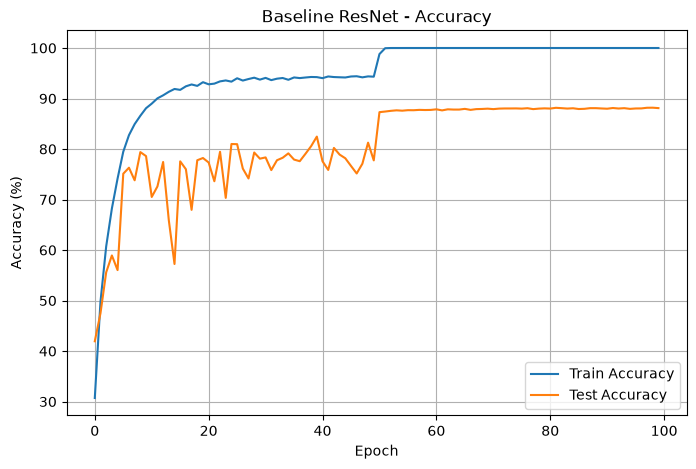

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label="Train Accuracy")
plt.plot(test_accuracies, label="Test Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Baseline ResNet - Accuracy")
plt.legend()
plt.grid()

plt.show()

### Baseline result save

In [ ]:
baseline_results = {
    "model": "ResNet",
    "parameters": total_params,
    "best_test_accuracy": best_test_acc,
    "best_epoch": best_epoch,
    "training_time_minutes": total_time / 60
}

print(baseline_results)

{'model': 'ResNet', 'parameters': 11173962, 'best_test_accuracy': 88.18, 'best_epoch': 99, 'training_time_minutes': 48.30593959490458}


### STEP 3: SE BLOCK

In [ ]:
import torch
import torch.nn as nn


class SEBlock(nn.Module):

    def __init__(self, channels, reduction=16):
        super(SEBlock, self).__init__()

        # Squeeze + Excitation
        self.se = nn.Sequential(

            # Squeeze: Global Average Pooling
            nn.AdaptiveAvgPool2d(1),

            # Channel reduction
            nn.Linear(channels, channels // reduction),

            # ReLU
            nn.ReLU(inplace=True),

            # Channel expansion
            nn.Linear(channels // reduction, channels),

            # Channel weights between 0 and 1
            nn.Sigmoid()
        )

    def forward(self, x):

        # x shape: [Batch, Channels, Height, Width]
        batch, channels, _, _ = x.size()

        # Squeeze
        y = nn.functional.adaptive_avg_pool2d(x, 1)

        # [B, C, 1, 1] -> [B, C]
        y = y.view(batch, channels)

        # Excitation
        y = self.se[1:](y)

        # [B, C] -> [B, C, 1, 1]
        y = y.view(batch, channels, 1, 1)

        # Scale
        return x * y

SE Block test

In [ ]:
# Example feature map
x = torch.randn(4, 64, 32, 32)

# Create SE block
se = SEBlock(channels=64, reduction=16)

# Forward pass
output = se(x)

print("Input shape :", x.shape)
print("Output shape:", output.shape)

Input shape : torch.Size([4, 64, 32, 32])
Output shape: torch.Size([4, 64, 32, 32])


New SEBasicBlock

In [ ]:
class SEBasicBlock(nn.Module):

    def __init__(self, in_channels, out_channels, stride=1, reduction=16):
        super(SEBasicBlock, self).__init__()

        # First convolution
        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            stride=stride,
            padding=1,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(out_channels)

        # Second convolution
        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(out_channels)

        # SE Block
        self.se = SEBlock(
            channels=out_channels,
            reduction=reduction
        )

        # Shortcut
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):

        identity = self.shortcut(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        # SE recalibration
        out = self.se(out)

        # Residual addition
        out = out + identity

        out = self.relu(out)

        return out

Test

In [ ]:
x = torch.randn(4, 64, 32, 32)

block = SEBasicBlock(
    in_channels=64,
    out_channels=64,
    reduction=16
)

output = block(x)

print("Input shape :", x.shape)
print("Output shape:", output.shape)

Input shape : torch.Size([4, 64, 32, 32])
Output shape: torch.Size([4, 64, 32, 32])


SE-ResNet code

In [ ]:
class SEResNet(nn.Module):

    def __init__(self, num_classes=10, reduction=16):
        super(SEResNet, self).__init__()

        self.in_channels = 64

        # Initial convolution
        self.conv1 = nn.Conv2d(
            3, 64,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)

        # Residual stages
        self.layer1 = self.make_layer(
            64, 2, stride=1, reduction=reduction
        )

        self.layer2 = self.make_layer(
            128, 2, stride=2, reduction=reduction
        )

        self.layer3 = self.make_layer(
            256, 2, stride=2, reduction=reduction
        )

        self.layer4 = self.make_layer(
            512, 2, stride=2, reduction=reduction
        )

        # Global Average Pooling
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))

        # Classifier
        self.fc = nn.Linear(512, num_classes)

    def make_layer(self, out_channels, blocks, stride, reduction):

        layers = []

        # First block
        layers.append(
            SEBasicBlock(
                self.in_channels,
                out_channels,
                stride,
                reduction
            )
        )

        self.in_channels = out_channels

        # Remaining blocks
        for _ in range(1, blocks):
            layers.append(
                SEBasicBlock(
                    out_channels,
                    out_channels,
                    stride=1,
                    reduction=reduction
                )
            )

        return nn.Sequential(*layers)

    def forward(self, x):

        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.avgpool(x)

        x = torch.flatten(x, 1)

        x = self.fc(x)

        return x

Create the model

In [ ]:
se_model = SEResNet(
    num_classes=10,
    reduction=16
).to(device)

print(se_model)

SEResNet(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (layer1): Sequential(
    (0): SEBasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (se): SEBlock(
        (se): Sequential(
          (0): AdaptiveAvgPool2d(output_size=1)
          (1): Linear(in_features=64, out_features=4, bias=True)
          (2): ReLU(inplace=True)
          (3): Linear(in_features=4, out_features=64, bias=True)
          (4): Sigmoid()
        )
      )
      (shortcut): Identity()
 

Count parameters

In [ ]:
se_total_params = sum(
    p.numel() for p in se_model.parameters()
)

se_trainable_params = sum(
    p.numel()
    for p in se_model.parameters()
    if p.requires_grad
)

print("SE-ResNet Total Parameters:", se_total_params)
print("SE-ResNet Trainable Parameters:", se_trainable_params)

SE-ResNet Total Parameters: 11263042
SE-ResNet Trainable Parameters: 11263042


Test one batch

In [ ]:
images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

with torch.no_grad():
    outputs = se_model(images)

print("Input shape :", images.shape)
print("Output shape:", outputs.shape)

Input shape : torch.Size([128, 3, 32, 32])
Output shape: torch.Size([128, 10])


In [ ]:

#LOSS FUNCTION
criterion_se = nn.CrossEntropyLoss()



optimizer_se = optim.SGD(
    se_model.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4
)

#LEARNING RATE SCHEDULER

scheduler_se = optim.lr_scheduler.MultiStepLR(
    optimizer_se,
    milestones=[50, 75],
    gamma=0.1
)

#NUMBER OF EPOCHS


num_epochs = 100


#LISTS TO STORE TRAINING RESULTS

se_train_losses = []
se_train_accuracies = []

se_test_losses = []
se_test_accuracies = []


# BEST MODEL TRACKING

best_se_test_acc = 0.0
best_se_epoch = 0


#VERIFY THE TRAINING SETU
print("SE-ResNet Training Setup")

print("Model              : SE-ResNet")
print("Number of Epochs   :", num_epochs)

print(
    "Initial Learning Rate:",
    optimizer_se.param_groups[0]["lr"]
)

print(
    "Momentum            :",
    optimizer_se.param_groups[0]["momentum"]
)

print(
    "Weight Decay        :",
    optimizer_se.param_groups[0]["weight_decay"]
)

print(
    "LR Scheduler        : MultiStepLR"
)

print(
    "LR Milestones       : [50, 75]"
)

print(
    "Reduction Factor    : 0.1"
)
print("SE-ResNet training setup is ready!")

SE-ResNet Training Setup
Model              : SE-ResNet
Number of Epochs   : 100
Initial Learning Rate: 0.1
Momentum            : 0.9
Weight Decay        : 0.0005
LR Scheduler        : MultiStepLR
LR Milestones       : [50, 75]
Reduction Factor    : 0.1
SE-ResNet training setup is ready!


In [ ]:

#TRAIN SE-RESNET

import time
# Start total training time
start_time = time.time()

# Train SE-ResNet for 100 epoch
for epoch in range(num_epochs):

    # Start timer for current epoch
    epoch_start = time.time()

    # TRAINING
    train_loss, train_acc = train_one_epoch(
        se_model,
        train_loader,
        criterion_se,
        optimizer_se,
        device
    )

    # TEST / VALIDATION
    test_loss, test_acc = evaluate(
        se_model,
        test_loader,
        criterion_se,
        device
    )

    # UPDATE LEARNING RATE
    scheduler_se.step()

    # STORE RESULTS
    se_train_losses.append(train_loss)
    se_train_accuracies.append(train_acc)

    se_test_losses.append(test_loss)
    se_test_accuracies.append(test_acc)

    # SAVE BEST MODEL
    if test_acc > best_se_test_acc:

        best_se_test_acc = test_acc
        best_se_epoch = epoch + 1

        torch.save(
            se_model.state_dict(),
            "se_resnet_best.pth"
        )

    # Epoch time
    epoch_time = time.time() - epoch_start

    # Print results
    print(
        f"Epoch [{epoch + 1:03d}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:.2f}% | "
        f"Time: {epoch_time:.1f}s"
    )

# Total training tim
total_se_time = time.time() - start_time

# Final training summar
print("SE-ResNet Training Complete!")

print(
    f"Best Test Accuracy : {best_se_test_acc:.2f}%"
)

print(
    f"Best Epoch         : {best_se_epoch}"
)

print(
    f"Total Training Time: {total_se_time / 60:.2f} minutes"
)

print(
    "Best model saved as: se_resnet_best.pth"
)


Epoch [001/100] Train Loss: 1.4344 | Train Acc: 47.79% | Test Loss: 1.3131 | Test Acc: 53.60% | Time: 30.6s
Epoch [002/100] Train Loss: 0.9005 | Train Acc: 67.92% | Test Loss: 1.0895 | Test Acc: 61.73% | Time: 30.6s
Epoch [003/100] Train Loss: 0.6764 | Train Acc: 76.17% | Test Loss: 0.7695 | Test Acc: 72.90% | Time: 30.8s
Epoch [004/100] Train Loss: 0.5546 | Train Acc: 80.63% | Test Loss: 0.6983 | Test Acc: 75.44% | Time: 30.7s
Epoch [005/100] Train Loss: 0.4574 | Train Acc: 84.03% | Test Loss: 0.7134 | Test Acc: 76.20% | Time: 30.6s
Epoch [006/100] Train Loss: 0.3983 | Train Acc: 86.09% | Test Loss: 0.7099 | Test Acc: 76.42% | Time: 30.6s
Epoch [007/100] Train Loss: 0.3496 | Train Acc: 87.85% | Test Loss: 0.6283 | Test Acc: 79.75% | Time: 31.0s
Epoch [008/100] Train Loss: 0.3197 | Train Acc: 89.05% | Test Loss: 0.6767 | Test Acc: 77.51% | Time: 30.6s
Epoch [009/100] Train Loss: 0.2931 | Train Acc: 89.90% | Test Loss: 0.6982 | Test Acc: 77.49% | Time: 30.6s
Epoch [010/100] Train Loss: 

In [ ]:

#BEST SE-RESNET MODEL & FINAL EVALUATION


# 1. Load the best SE-ResNet weights


se_model.load_state_dict(
    torch.load(
        "se_resnet_best.pth",
        map_location=device
    )
)

# Set model to evaluation mode
se_model.eval()



# 2. Final evaluation on the test dataset


final_se_loss, final_se_acc = evaluate(
    se_model,
    test_loader,
    criterion_se,
    device
)



# 3. Print final results


print("SE-ResNet Final Evaluation")

print(
    f"Final Test Loss     : {final_se_loss:.4f}"
)

print(
    f"Final Test Accuracy : {final_se_acc:.2f}%"
)

print(
    f"Best Test Accuracy  : {best_se_test_acc:.2f}%"
)

print(
    f"Best Epoch          : {best_se_epoch}"
)

print(
    f"Training Time       : {total_se_time / 60:.2f} minutes"
)


SE-ResNet Final Evaluation
Final Test Loss     : 0.3916
Final Test Accuracy : 88.53%
Best Test Accuracy  : 88.53%
Best Epoch          : 66
Training Time       : 72.52 minutes


Training Graphs

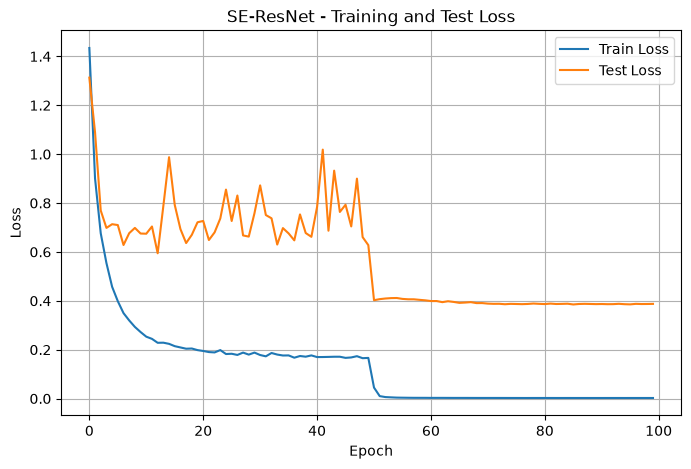

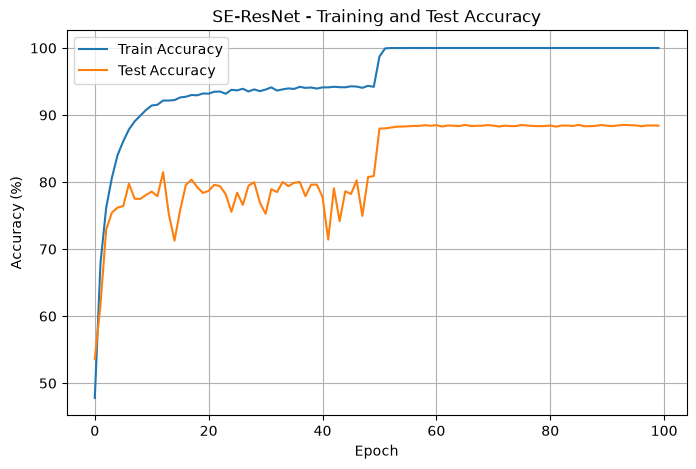

In [ ]:
# ============================================================
# STEP 3.7 — SE-RESNET TRAINING GRAPHS
# ============================================================

import matplotlib.pyplot as plt


# 1. LOSS CURVE

plt.figure(figsize=(8, 5))

plt.plot(
    se_train_losses,
    label="Train Loss"
)

plt.plot(
    se_test_losses,
    label="Test Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("SE-ResNet - Training and Test Loss")

plt.legend()
plt.grid()

plt.show()


# 2. ACCURACY CURVE

plt.figure(figsize=(8, 5))

plt.plot(
    se_train_accuracies,
    label="Train Accuracy"
)

plt.plot(
    se_test_accuracies,
    label="Test Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title("SE-ResNet - Training and Test Accuracy")

plt.legend()
plt.grid()

plt.show()

BASELINE RESNET vs SE-RESNET

In [ ]:


# 1. Create comparison dictionary

comparison = {
    "Model": [
        "Baseline ResNet",
        "SE-ResNet"
    ],

    "Parameters": [
        total_params,
        se_total_params
    ],

    "Best Test Accuracy (%)": [
        best_test_acc,
        best_se_test_acc
    ],

    "Best Epoch": [
        best_epoch,
        best_se_epoch
    ],

    "Training Time (minutes)": [
        total_time / 60,
        total_se_time / 60
    ]
}


# 2. Display comparison

import pandas as pd

comparison_df = pd.DataFrame(comparison)

print("BASELINE RESNET vs SE-RESNET")

display(comparison_df)

BASELINE RESNET vs SE-RESNET


,Model,Parameters,Best Test Accuracy (%),Best Epoch,Training Time (minutes)
0,Baseline ResNet,11173962,88.18,99,48.305940
1,SE-ResNet,11263042,88.53,66,72.517131


In [ ]:

# ACCURACY IMPROVEMENT

accuracy_improvement = best_se_test_acc - best_test_acc

print("Baseline ResNet Accuracy :", f"{best_test_acc:.2f}%")
print("SE-ResNet Accuracy       :", f"{best_se_test_acc:.2f}%")

print(
    "Accuracy Improvement     :",
    f"{accuracy_improvement:+.2f} percentage points"
)

Baseline ResNet Accuracy : 88.18%
SE-ResNet Accuracy       : 88.53%
Accuracy Improvement     : +0.35 percentage points


In [ ]:

#PARAMETER OVERHEAD

parameter_increase = se_total_params - total_params

parameter_overhead_percent = (
    parameter_increase / total_params
) * 100

print("Baseline Parameters :", total_params)
print("SE-ResNet Parameters:", se_total_params)

print(
    "Additional Parameters:",
    parameter_increase
)

print(
    "Parameter Overhead:",
    f"{parameter_overhead_percent:.2f}%"
)

Baseline Parameters : 11173962
SE-ResNet Parameters: 11263042
Additional Parameters: 89080
Parameter Overhead: 0.80%


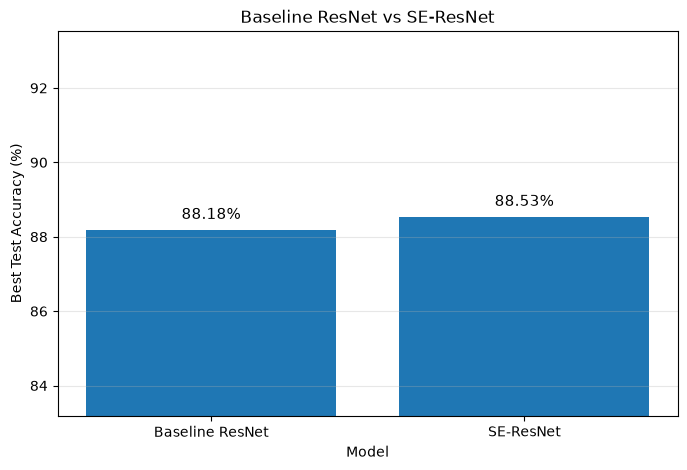

In [ ]:
# ACCURACY COMPARISON

import matplotlib.pyplot as plt


# Model names

models = [
    "Baseline ResNet",
    "SE-ResNet"
]


# Best test accuracies

accuracies = [
    best_test_acc,
    best_se_test_acc
]


# Create bar chart

plt.figure(figsize=(8, 5))

bars = plt.bar(
    models,
    accuracies
)


# Add accuracy values on top of bars

for bar, accuracy in zip(bars, accuracies):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{accuracy:.2f}%",
        ha="center",
        fontsize=11
    )



# Labels and title

plt.xlabel("Model")
plt.ylabel("Best Test Accuracy (%)")

plt.title(
    "Baseline ResNet vs SE-ResNet"
)

plt.ylim(
    max(0, min(accuracies) - 5),
    min(100, max(accuracies) + 5)
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

Parameters:
Baseline ResNet: 11173962
SE-ResNet: 11263042

Training Time:
Baseline ResNet: 48.31 minutes
SE-ResNet: 72.52 minutes


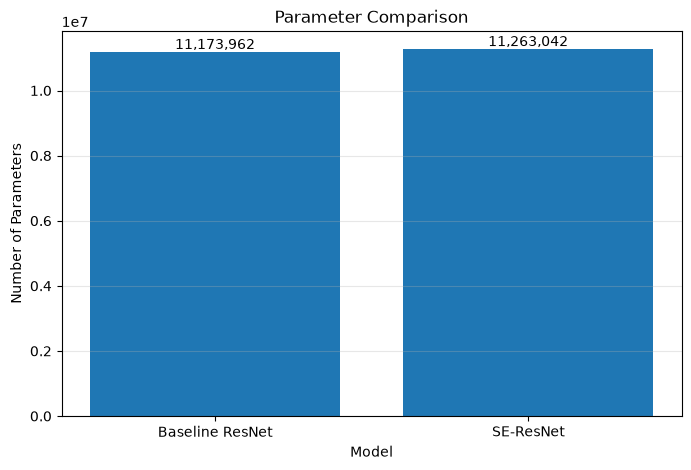

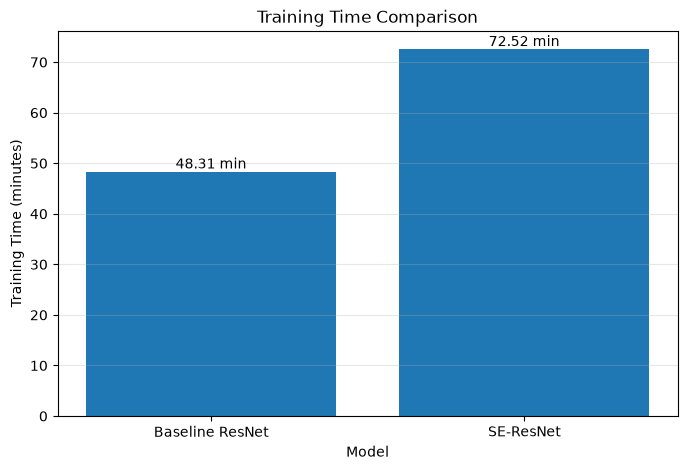

In [ ]:
# Parameter comparison

models = [
    "Baseline ResNet",
    "SE-ResNet"
]

parameters = [
    total_params,
    se_total_params
]

training_times = [
    total_time / 60,
    total_se_time / 60
]

print("Parameters:")
print("Baseline ResNet:", total_params)
print("SE-ResNet:", se_total_params)

print("\nTraining Time:")
print("Baseline ResNet:", f"{total_time / 60:.2f} minutes")
print("SE-ResNet:", f"{total_se_time / 60:.2f} minutes")


# Parameter comparison graph

plt.figure(figsize=(8, 5))

bars = plt.bar(models, parameters)

for bar, value in zip(bars, parameters):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Model")
plt.ylabel("Number of Parameters")
plt.title("Parameter Comparison")

plt.grid(axis="y", alpha=0.3)
plt.show()


# Training time comparison graph

plt.figure(figsize=(8, 5))

bars = plt.bar(models, training_times)

for bar, value in zip(bars, training_times):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f} min",
        ha="center",
        va="bottom"
    )

plt.xlabel("Model")
plt.ylabel("Training Time (minutes)")
plt.title("Training Time Comparison")

plt.grid(axis="y", alpha=0.3)
plt.show()

Ablation Study

First model

In [ ]:
se_model_r4 = SEResNet(
    num_classes=10,
    reduction=4
).to(device)

r4_params = sum(
    p.numel()
    for p in se_model_r4.parameters()
)

print("SE-ResNet r=4")
print("Parameters:", r4_params)

SE-ResNet r=4
Parameters: 11524522


In [ ]:
import os
import time
import torch
# Loss function

criterion_r4 = nn.CrossEntropyLoss()

# Optimizer

optimizer_r4 = optim.SGD(
    se_model_r4.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4
)

# Learning rate scheduler

scheduler_r4 = optim.lr_scheduler.MultiStepLR(
    optimizer_r4,
    milestones=[50, 75],
    gamma=0.1
)

# Training settings

num_epochs_r4 = 100

r4_train_losses = []
r4_train_accuracies = []

r4_test_losses = []
r4_test_accuracies = []

best_r4_test_acc = 0.0
best_r4_epoch = 0

# Checkpoint directory
checkpoint_dir_r4 = "checkpoints/se_resnet_r4"
os.makedirs(checkpoint_dir_r4, exist_ok=True)

# Early stopping settings
patience_r4 = 10
min_delta_r4 = 0.01  # Accuracy improvement in percentage points
early_stop_counter_r4 = 0

# Best model tracking
best_r4_test_acc = 0.0
best_r4_epoch = 0

# Resume settings
start_epoch_r4 = 0

# Initialize metric histories if not already defined
if "r4_train_losses" not in globals():
    r4_train_losses = []
if "r4_train_accuracies" not in globals():
    r4_train_accuracies = []
if "r4_test_losses" not in globals():
    r4_test_losses = []
if "r4_test_accuracies" not in globals():
    r4_test_accuracies = []


print("SE-ResNet r=4 training setup ready!")
print("Epochs:", num_epochs_r4)
print("Learning Rate:", optimizer_r4.param_groups[0]["lr"])

SE-ResNet r=4 training setup ready!
Epochs: 100
Learning Rate: 0.1


In [ ]:

checkpoint_path_r4 = os.path.join(
    checkpoint_dir_r4,
    "latest_checkpoint.pth"
)

if os.path.exists(checkpoint_path_r4):

    checkpoint = torch.load(
        checkpoint_path_r4,
        map_location=device,
        weights_only=True
    )

    se_model_r4.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer_r4.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    scheduler_r4.load_state_dict(
        checkpoint["scheduler_state_dict"]
    )

    start_epoch_r4 = checkpoint["epoch"]
    best_r4_test_acc = checkpoint["best_test_acc"]
    best_r4_epoch = checkpoint["best_epoch"]
    early_stop_counter_r4 = checkpoint["early_stop_counter"]

    print(f"Resuming from epoch {start_epoch_r4 + 1}")
    print(f"Best accuracy so far: {best_r4_test_acc:.2f}%")

else:
    print("No checkpoint found. Starting from scratch.")



start_time_r4 = time.time()

for epoch in range(start_epoch_r4, num_epochs_r4):

    epoch_start = time.time()

    train_loss, train_acc = train_one_epoch(
        se_model_r4,
        train_loader,
        criterion_r4,
        optimizer_r4,
        device
    )

    test_loss, test_acc = evaluate(
        se_model_r4,
        test_loader,
        criterion_r4,
        device
    )

    scheduler_r4.step()

    # Store metrics
    r4_train_losses.append(train_loss)
    r4_train_accuracies.append(train_acc)
    r4_test_losses.append(test_loss)
    r4_test_accuracies.append(test_acc)

    # 1. Save best model and update early stopping
    if test_acc > best_r4_test_acc + min_delta_r4:

        best_r4_test_acc = test_acc
        best_r4_epoch = epoch + 1
        early_stop_counter_r4 = 0

        torch.save(
            se_model_r4.state_dict(),
            os.path.join(
                checkpoint_dir_r4,
                "best_model.pth"
            )
        )

        print("Best model saved!")

    else:
        early_stop_counter_r4 += 1

    # 2. Save periodic checkpoint every 5 epochs
    if (epoch + 1) % 5 == 0:

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": se_model_r4.state_dict(),
                "optimizer_state_dict": optimizer_r4.state_dict(),
                "scheduler_state_dict": scheduler_r4.state_dict(),
                "best_test_acc": best_r4_test_acc,
                "best_epoch": best_r4_epoch,
                "early_stop_counter": early_stop_counter_r4,
                "train_loss": train_loss,
                "train_acc": train_acc,
                "test_loss": test_loss,
                "test_acc": test_acc,
            },
            os.path.join(
                checkpoint_dir_r4,
                f"checkpoint_epoch_{epoch + 1:03d}.pth"
            )
        )

    # 3. Save latest full checkpoint every epoch
    torch.save(
        {
            "epoch": epoch + 1,
            "model_state_dict": se_model_r4.state_dict(),
            "optimizer_state_dict": optimizer_r4.state_dict(),
            "scheduler_state_dict": scheduler_r4.state_dict(),
            "best_test_acc": best_r4_test_acc,
            "best_epoch": best_r4_epoch,
            "early_stop_counter": early_stop_counter_r4,
        },
        os.path.join(
            checkpoint_dir_r4,
            "latest_checkpoint.pth"
        )
    )

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch [{epoch + 1:03d}/{num_epochs_r4}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:.2f}% | "
        f"Best Acc: {best_r4_test_acc:.2f}% | "
        f"Time: {epoch_time:.1f}s"
    )

    # 4. Early stopping
    if early_stop_counter_r4 >= patience_r4:

        print(
            f"\nEarly stopping triggered at epoch {epoch + 1}."
        )
        print(f"Best epoch: {best_r4_epoch}")
        print(f"Best accuracy: {best_r4_test_acc:.2f}%")
        break

total_time_r4 = time.time() - start_time_r4

print("\nSE-ResNet r=4 training complete!")
print(f"Best Test Accuracy: {best_r4_test_acc:.2f}%")
print(f"Best Epoch: {best_r4_epoch}")
print(f"Training Time: {total_time_r4 / 60:.2f} minutes")
print(f"Checkpoints saved in: {checkpoint_dir_r4}")


No checkpoint found. Starting from scratch.
Best model saved!
Epoch [001/100] Train Loss: 1.5144 | Train Acc: 44.17% | Test Loss: 1.6640 | Test Acc: 46.05% | Best Acc: 46.05% | Time: 30.7s
Best model saved!
Epoch [002/100] Train Loss: 0.9646 | Train Acc: 65.46% | Test Loss: 1.3455 | Test Acc: 57.95% | Best Acc: 57.95% | Time: 30.8s
Best model saved!
Epoch [003/100] Train Loss: 0.7090 | Train Acc: 75.16% | Test Loss: 0.9954 | Test Acc: 67.80% | Best Acc: 67.80% | Time: 30.7s
Best model saved!
Epoch [004/100] Train Loss: 0.5699 | Train Acc: 80.07% | Test Loss: 0.7215 | Test Acc: 75.16% | Best Acc: 75.16% | Time: 30.6s
Epoch [005/100] Train Loss: 0.4758 | Train Acc: 83.34% | Test Loss: 0.8937 | Test Acc: 70.63% | Best Acc: 75.16% | Time: 31.1s
Best model saved!
Epoch [006/100] Train Loss: 0.4045 | Train Acc: 86.01% | Test Loss: 0.6335 | Test Acc: 77.99% | Best Acc: 77.99% | Time: 30.8s
Epoch [007/100] Train Loss: 0.3643 | Train Acc: 87.37% | Test Loss: 0.6844 | Test Acc: 76.90% | Best Acc

In [ ]:
se_model_r8 = SEResNet(
    num_classes=10,
    reduction=8
).to(device)

r8_params = sum(
    p.numel()
    for p in se_model_r8.parameters()
)

print("SE-ResNet r=8")
print("Parameters:", r8_params)

SE-ResNet r=8
Parameters: 11350202


In [ ]:
criterion_r8 = nn.CrossEntropyLoss()

optimizer_r8 = optim.SGD(
    se_model_r8.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4
)

scheduler_r8 = optim.lr_scheduler.MultiStepLR(
    optimizer_r8,
    milestones=[50, 75],
    gamma=0.1
)

# Early Stopping settings
patience_r8 = 10
early_stop_counter_r8 = 0
min_delta_r8 = 0.01  # Minimum accuracy improvement, in percentage points

num_epochs_r8 = 100

r8_train_losses = []
r8_train_accuracies = []

r8_test_losses = []
r8_test_accuracies = []

best_r8_test_acc = 0.0
best_r8_epoch = 0

print("SE-ResNet r=8 training setup ready!")
print("Epochs:", num_epochs_r8)
print("Learning Rate:", optimizer_r8.param_groups[0]["lr"])

SE-ResNet r=8 training setup ready!
Epochs: 100
Learning Rate: 0.1


In [ ]:

# ==================== SE-ResNet r=8 Training ====================

import os
import time
import torch

# Checkpoint directory (missing in your original r=8 setup)
checkpoint_dir_r8 = "checkpoints/se_resnet_r8"
os.makedirs(checkpoint_dir_r8, exist_ok=True)

checkpoint_path_r8 = os.path.join(
    checkpoint_dir_r8,
    "latest_checkpoint.pth"
)

# Resume settings
start_epoch_r8 = 0

# Resume from the latest checkpoint if one exists
if os.path.exists(checkpoint_path_r8):

    checkpoint = torch.load(
        checkpoint_path_r8,
        map_location=device,
        weights_only=True
    )

    se_model_r8.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer_r8.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    scheduler_r8.load_state_dict(
        checkpoint["scheduler_state_dict"]
    )

    start_epoch_r8 = checkpoint["epoch"]
    best_r8_test_acc = checkpoint["best_test_acc"]
    best_r8_epoch = checkpoint["best_epoch"]
    early_stop_counter_r8 = checkpoint["early_stop_counter"]

    print(f"Resuming from epoch {start_epoch_r8 + 1}")
    print(f"Best accuracy so far: {best_r8_test_acc:.2f}%")

else:
    print("No checkpoint found. Starting from scratch.")

# ==================== Training Loop ====================

start_time_r8 = time.time()

for epoch in range(start_epoch_r8, num_epochs_r8):

    epoch_start = time.time()

    # Train
    train_loss, train_acc = train_one_epoch(
        se_model_r8,
        train_loader,
        criterion_r8,
        optimizer_r8,
        device
    )

    # Evaluate
    test_loss, test_acc = evaluate(
        se_model_r8,
        test_loader,
        criterion_r8,
        device
    )

    # Update learning rate
    scheduler_r8.step()

    # Store metrics
    r8_train_losses.append(train_loss)
    r8_train_accuracies.append(train_acc)
    r8_test_losses.append(test_loss)
    r8_test_accuracies.append(test_acc)

    # Save best model and update early stopping counter
    if test_acc > best_r8_test_acc + min_delta_r8:

        best_r8_test_acc = test_acc
        best_r8_epoch = epoch + 1
        early_stop_counter_r8 = 0

        torch.save(
            se_model_r8.state_dict(),
            os.path.join(
                checkpoint_dir_r8,
                "best_model.pth"
            )
        )

        print("Best model saved!")

    else:
        early_stop_counter_r8 += 1

    # Save a periodic checkpoint every 5 epochs
    if (epoch + 1) % 5 == 0:

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": se_model_r8.state_dict(),
                "optimizer_state_dict": optimizer_r8.state_dict(),
                "scheduler_state_dict": scheduler_r8.state_dict(),
                "best_test_acc": best_r8_test_acc,
                "best_epoch": best_r8_epoch,
                "early_stop_counter": early_stop_counter_r8,
                "train_loss": train_loss,
                "train_acc": train_acc,
                "test_loss": test_loss,
                "test_acc": test_acc,
            },
            os.path.join(
                checkpoint_dir_r8,
                f"checkpoint_epoch_{epoch + 1:03d}.pth"
            )
        )

    # Save latest checkpoint after every epoch
    torch.save(
        {
            "epoch": epoch + 1,
            "model_state_dict": se_model_r8.state_dict(),
            "optimizer_state_dict": optimizer_r8.state_dict(),
            "scheduler_state_dict": scheduler_r8.state_dict(),
            "best_test_acc": best_r8_test_acc,
            "best_epoch": best_r8_epoch,
            "early_stop_counter": early_stop_counter_r8,
        },
        checkpoint_path_r8
    )

    # Print epoch progress
    epoch_time = time.time() - epoch_start

    print(
        f"Epoch [{epoch + 1:03d}/{num_epochs_r8}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:.2f}% | "
        f"Best Acc: {best_r8_test_acc:.2f}% | "
        f"Time: {epoch_time:.1f}s",
        flush=True
    )

    # Early stopping
    if early_stop_counter_r8 >= patience_r8:

        print(
            f"\nEarly stopping triggered at epoch {epoch + 1}."
        )
        print(f"Best epoch: {best_r8_epoch}")
        print(f"Best accuracy: {best_r8_test_acc:.2f}%")
        break

# ==================== Final Summary ====================

total_time_r8 = time.time() - start_time_r8

print("\nSE-ResNet r=8 training complete!")
print(f"Best Test Accuracy: {best_r8_test_acc:.2f}%")
print(f"Best Epoch: {best_r8_epoch}")
print(f"Training Time: {total_time_r8 / 60:.2f} minutes")
print(f"Checkpoints saved in: {checkpoint_dir_r8}")


No checkpoint found. Starting from scratch.
Best model saved!
Epoch [001/100] Train Loss: 0.1624 | Train Acc: 94.40% | Test Loss: 0.5753 | Test Acc: 81.84% | Best Acc: 81.84% | Time: 31.2s
Epoch [002/100] Train Loss: 0.1679 | Train Acc: 94.25% | Test Loss: 0.6182 | Test Acc: 81.53% | Best Acc: 81.84% | Time: 31.4s
Epoch [003/100] Train Loss: 0.1631 | Train Acc: 94.43% | Test Loss: 0.7464 | Test Acc: 78.36% | Best Acc: 81.84% | Time: 31.1s
Best model saved!
Epoch [004/100] Train Loss: 0.0441 | Train Acc: 98.81% | Test Loss: 0.4145 | Test Acc: 87.40% | Best Acc: 87.40% | Time: 31.2s
Best model saved!
Epoch [005/100] Train Loss: 0.0095 | Train Acc: 99.95% | Test Loss: 0.4196 | Test Acc: 87.62% | Best Acc: 87.62% | Time: 31.6s
Best model saved!
Epoch [006/100] Train Loss: 0.0060 | Train Acc: 99.99% | Test Loss: 0.4160 | Test Acc: 87.66% | Best Acc: 87.66% | Time: 30.6s
Best model saved!
Epoch [007/100] Train Loss: 0.0046 | Train Acc: 100.00% | Test Loss: 0.4206 | Test Acc: 87.77% | Best Ac

In [ ]:
se_model_r16 = SEResNet(
    num_classes=10,
    reduction=16
).to(device)

r16_params = sum(
    p.numel()
    for p in se_model_r16.parameters()
)

print("SE-ResNet r=16")
print("Parameters:", r16_params)

SE-ResNet r=16
Parameters: 11263042


In [ ]:
criterion_r16 = nn.CrossEntropyLoss()

optimizer_r16 = optim.SGD(
    se_model_r16.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4
)

scheduler_r16 = optim.lr_scheduler.MultiStepLR(
    optimizer_r16,
    milestones=[50, 75],
    gamma=0.1
)

# Checkpoint directory
checkpoint_dir_r16 = "checkpoints/se_resnet_r16"
os.makedirs(checkpoint_dir_r16, exist_ok=True)

# Early stopping settings
patience_r16 = 10
min_delta_r16 = 0.01  # Accuracy improvement in percentage points
early_stop_counter_r16 = 0

# Best model tracking
best_r16_test_acc = 0.0
best_r16_epoch = 0

# Starting epoch
start_epoch_r16 = 0

# Metric histories (initialize only if not already defined)
if "r16_train_losses" not in globals():
    r16_train_losses = []
if "r16_train_accuracies" not in globals():
    r16_train_accuracies = []
if "r16_test_losses" not in globals():
    r16_test_losses = []
if "r16_test_accuracies" not in globals():
    r16_test_accuracies = []

num_epochs_r16 = 100

r16_train_losses = []
r16_train_accuracies = []

r16_test_losses = []
r16_test_accuracies = []

best_r16_test_acc = 0.0
best_r16_epoch = 0

print("SE-ResNet r=16 training setup ready!")
print("Epochs:", num_epochs_r16)
print("Learning Rate:", optimizer_r16.param_groups[0]["lr"])

SE-ResNet r=16 training setup ready!
Epochs: 100
Learning Rate: 0.1


In [ ]:
checkpoint_path_r16 = os.path.join(
    checkpoint_dir_r16,
    "latest_checkpoint.pth"
)

if os.path.exists(checkpoint_path_r16):

    checkpoint = torch.load(
        checkpoint_path_r16,
        map_location=device,
        weights_only=True
    )

    se_model_r16.load_state_dict(
        checkpoint["model_state_dict"]
    )
    optimizer_r16.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )
    scheduler_r16.load_state_dict(
        checkpoint["scheduler_state_dict"]
    )

    start_epoch_r16 = checkpoint["epoch"]
    best_r16_test_acc = checkpoint["best_test_acc"]
    best_r16_epoch = checkpoint["best_epoch"]
    early_stop_counter_r16 = checkpoint["early_stop_counter"]

    print(f"Resuming from epoch {start_epoch_r16 + 1}")

else:
    print("No checkpoint found. Starting from scratch.")

start_time_r16 = time.time()

for epoch in range(start_epoch_r16, num_epochs_r16):

    epoch_start = time.time()

    train_loss, train_acc = train_one_epoch(
        se_model_r16,
        train_loader,
        criterion_r16,
        optimizer_r16,
        device
    )

    test_loss, test_acc = evaluate(
        se_model_r16,
        test_loader,
        criterion_r16,
        device
    )

    scheduler_r16.step()

    # Store metrics
    r16_train_losses.append(train_loss)
    r16_train_accuracies.append(train_acc)
    r16_test_losses.append(test_loss)
    r16_test_accuracies.append(test_acc)

    # 1. Save best model and update early stopping counter
    if test_acc > best_r16_test_acc + min_delta_r16:

        best_r16_test_acc = test_acc
        best_r16_epoch = epoch + 1
        early_stop_counter_r16 = 0

        torch.save(
            se_model_r16.state_dict(),
            os.path.join(
                checkpoint_dir_r16,
                "best_model.pth"
            )
        )

        print("Best model saved!")

    else:
        early_stop_counter_r16 += 1

    # 2. Save periodic checkpoint every 5 epochs
    if (epoch + 1) % 5 == 0:

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": se_model_r16.state_dict(),
                "optimizer_state_dict": optimizer_r16.state_dict(),
                "scheduler_state_dict": scheduler_r16.state_dict(),
                "best_test_acc": best_r16_test_acc,
                "best_epoch": best_r16_epoch,
                "early_stop_counter": early_stop_counter_r16,
                "train_loss": train_loss,
                "train_acc": train_acc,
                "test_loss": test_loss,
                "test_acc": test_acc,
            },
            os.path.join(
                checkpoint_dir_r16,
                f"checkpoint_epoch_{epoch + 1:03d}.pth"
            )
        )

    # 3. Save latest full checkpoint every epoch
    torch.save(
        {
            "epoch": epoch + 1,
            "model_state_dict": se_model_r16.state_dict(),
            "optimizer_state_dict": optimizer_r16.state_dict(),
            "scheduler_state_dict": scheduler_r16.state_dict(),
            "best_test_acc": best_r16_test_acc,
            "best_epoch": best_r16_epoch,
            "early_stop_counter": early_stop_counter_r16,
        },
        os.path.join(
            checkpoint_dir_r16,
            "latest_checkpoint.pth"
        )
    )

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch [{epoch + 1:03d}/{num_epochs_r16}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:.2f}% | "
        f"Best Acc: {best_r16_test_acc:.2f}% | "
        f"Time: {epoch_time:.1f}s"
    )

    # 4. Early stopping
    if early_stop_counter_r16 >= patience_r16:

        print(
            f"\nEarly stopping triggered at epoch {epoch + 1}."
        )
        print(f"Best epoch: {best_r16_epoch}")
        print(f"Best accuracy: {best_r16_test_acc:.2f}%")
        break

total_time_r16 = time.time() - start_time_r16

print("\nSE-ResNet r=16 training complete!")
print(f"Best Test Accuracy: {best_r16_test_acc:.2f}%")
print(f"Best Epoch: {best_r16_epoch}")
print(f"Training Time: {total_time_r16 / 60:.2f} minutes")
print(f"Checkpoints saved in: {checkpoint_dir_r16}")


No checkpoint found. Starting from scratch.
Best model saved!
Epoch [001/100] Train Loss: 1.4624 | Train Acc: 46.69% | Test Loss: 1.2103 | Test Acc: 55.95% | Best Acc: 55.95% | Time: 31.2s
Best model saved!
Epoch [002/100] Train Loss: 0.9083 | Train Acc: 67.85% | Test Loss: 0.9339 | Test Acc: 68.16% | Best Acc: 68.16% | Time: 31.6s
Best model saved!
Epoch [003/100] Train Loss: 0.6784 | Train Acc: 76.22% | Test Loss: 0.8483 | Test Acc: 71.13% | Best Acc: 71.13% | Time: 30.7s
Best model saved!
Epoch [004/100] Train Loss: 0.5399 | Train Acc: 81.20% | Test Loss: 0.7991 | Test Acc: 72.70% | Best Acc: 72.70% | Time: 30.7s
Best model saved!
Epoch [005/100] Train Loss: 0.4538 | Train Acc: 84.26% | Test Loss: 0.7334 | Test Acc: 75.39% | Best Acc: 75.39% | Time: 31.0s
Best model saved!
Epoch [006/100] Train Loss: 0.3922 | Train Acc: 86.38% | Test Loss: 0.6839 | Test Acc: 77.46% | Best Acc: 77.46% | Time: 30.6s
Best model saved!
Epoch [007/100] Train Loss: 0.3507 | Train Acc: 87.83% | Test Loss: 

In [ ]:
se_model_r32 = SEResNet(
    num_classes=10,
    reduction=32
).to(device)

r32_params = sum(
    p.numel()
    for p in se_model_r32.parameters()
)

print("SE-ResNet r=32")
print("Parameters:", r32_params)

SE-ResNet r=32
Parameters: 11219462


In [ ]:
criterion_r32 = nn.CrossEntropyLoss()

optimizer_r32 = optim.SGD(
    se_model_r32.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4
)

scheduler_r32 = optim.lr_scheduler.MultiStepLR(
    optimizer_r32,
    milestones=[50, 75],
    gamma=0.1
)

# Checkpoint directory
checkpoint_dir_r32 = "checkpoints/se_resnet_r32"
os.makedirs(checkpoint_dir_r32, exist_ok=True)

# Early stopping settings
patience_r32 = 10
min_delta_r32 = 0.01  # Percentage-point improvement
early_stop_counter_r32 = 0

# Best model tracking
best_r32_test_acc = 0.0
best_r32_epoch = 0

# Resume settings
start_epoch_r32 = 0

# Initialize metric histories if not already defined
if "r32_train_losses" not in globals():
    r32_train_losses = []
if "r32_train_accuracies" not in globals():
    r32_train_accuracies = []
if "r32_test_losses" not in globals():
    r32_test_losses = []
if "r32_test_accuracies" not in globals():
    r32_test_accuracies = []


num_epochs_r32 = 100

r32_train_losses = []
r32_train_accuracies = []

r32_test_losses = []
r32_test_accuracies = []

best_r32_test_acc = 0.0
best_r32_epoch = 0

print("SE-ResNet r=32 training setup ready!")
print("Epochs:", num_epochs_r32)
print("Learning Rate:", optimizer_r32.param_groups[0]["lr"])

SE-ResNet r=32 training setup ready!
Epochs: 100
Learning Rate: 0.1


In [ ]:
checkpoint_path_r32 = os.path.join(
    checkpoint_dir_r32,
    "latest_checkpoint.pth"
)

if os.path.exists(checkpoint_path_r32):

    checkpoint = torch.load(
        checkpoint_path_r32,
        map_location=device,
        weights_only=True
    )

    se_model_r32.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer_r32.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    scheduler_r32.load_state_dict(
        checkpoint["scheduler_state_dict"]
    )

    start_epoch_r32 = checkpoint["epoch"]
    best_r32_test_acc = checkpoint["best_test_acc"]
    best_r32_epoch = checkpoint["best_epoch"]
    early_stop_counter_r32 = checkpoint["early_stop_counter"]

    print(f"Resuming from epoch {start_epoch_r32 + 1}")
    print(f"Best accuracy so far: {best_r32_test_acc:.2f}%")

else:
    print("No checkpoint found. Starting from scratch.")

start_time_r32 = time.time()

for epoch in range(start_epoch_r32, num_epochs_r32):

    epoch_start = time.time()

    train_loss, train_acc = train_one_epoch(
        se_model_r32,
        train_loader,
        criterion_r32,
        optimizer_r32,
        device
    )

    test_loss, test_acc = evaluate(
        se_model_r32,
        test_loader,
        criterion_r32,
        device
    )

    scheduler_r32.step()

    # Store metrics
    r32_train_losses.append(train_loss)
    r32_train_accuracies.append(train_acc)
    r32_test_losses.append(test_loss)
    r32_test_accuracies.append(test_acc)

    # 1. Save best model and update early stopping
    if test_acc > best_r32_test_acc + min_delta_r32:

        best_r32_test_acc = test_acc
        best_r32_epoch = epoch + 1
        early_stop_counter_r32 = 0

        torch.save(
            se_model_r32.state_dict(),
            os.path.join(
                checkpoint_dir_r32,
                "best_model.pth"
            )
        )

        print("Best model saved!")

    else:
        early_stop_counter_r32 += 1

    # 2. Save periodic checkpoint every 5 epochs
    if (epoch + 1) % 5 == 0:

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": se_model_r32.state_dict(),
                "optimizer_state_dict": optimizer_r32.state_dict(),
                "scheduler_state_dict": scheduler_r32.state_dict(),
                "best_test_acc": best_r32_test_acc,
                "best_epoch": best_r32_epoch,
                "early_stop_counter": early_stop_counter_r32,
                "train_loss": train_loss,
                "train_acc": train_acc,
                "test_loss": test_loss,
                "test_acc": test_acc,
            },
            os.path.join(
                checkpoint_dir_r32,
                f"checkpoint_epoch_{epoch + 1:03d}.pth"
            )
        )

    # 3. Save latest full checkpoint every epoch
    torch.save(
        {
            "epoch": epoch + 1,
            "model_state_dict": se_model_r32.state_dict(),
            "optimizer_state_dict": optimizer_r32.state_dict(),
            "scheduler_state_dict": scheduler_r32.state_dict(),
            "best_test_acc": best_r32_test_acc,
            "best_epoch": best_r32_epoch,
            "early_stop_counter": early_stop_counter_r32,
        },
        os.path.join(
            checkpoint_dir_r32,
            "latest_checkpoint.pth"
        )
    )

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch [{epoch + 1:03d}/{num_epochs_r32}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:.2f}% | "
        f"Best Acc: {best_r32_test_acc:.2f}% | "
        f"Time: {epoch_time:.1f}s"
    )

    # 4. Early stopping
    if early_stop_counter_r32 >= patience_r32:

        print(
            f"\nEarly stopping triggered at epoch {epoch + 1}."
        )
        print(f"Best epoch: {best_r32_epoch}")
        print(f"Best accuracy: {best_r32_test_acc:.2f}%")
        break

total_time_r32 = time.time() - start_time_r32

print("\nSE-ResNet r=32 training complete!")
print(f"Best Test Accuracy: {best_r32_test_acc:.2f}%")
print(f"Best Epoch: {best_r32_epoch}")
print(f"Training Time: {total_time_r32 / 60:.2f} minutes")
print(f"Checkpoints saved in: {checkpoint_dir_r32}")


No checkpoint found. Starting from scratch.
Best model saved!
Epoch [001/100] Train Loss: 1.4748 | Train Acc: 46.05% | Test Loss: 1.2691 | Test Acc: 55.35% | Best Acc: 55.35% | Time: 31.1s
Best model saved!
Epoch [002/100] Train Loss: 0.9362 | Train Acc: 66.42% | Test Loss: 1.2787 | Test Acc: 55.58% | Best Acc: 55.58% | Time: 31.4s
Best model saved!
Epoch [003/100] Train Loss: 0.7095 | Train Acc: 74.90% | Test Loss: 0.8089 | Test Acc: 71.88% | Best Acc: 71.88% | Time: 31.1s
Best model saved!
Epoch [004/100] Train Loss: 0.5688 | Train Acc: 80.34% | Test Loss: 0.6593 | Test Acc: 77.27% | Best Acc: 77.27% | Time: 31.2s
Epoch [005/100] Train Loss: 0.4771 | Train Acc: 83.35% | Test Loss: 0.7928 | Test Acc: 74.46% | Best Acc: 77.27% | Time: 31.1s
Best model saved!
Epoch [006/100] Train Loss: 0.4068 | Train Acc: 85.87% | Test Loss: 0.6575 | Test Acc: 78.06% | Best Acc: 78.06% | Time: 31.1s
Best model saved!
Epoch [007/100] Train Loss: 0.3621 | Train Acc: 87.40% | Test Loss: 0.6206 | Test Acc:

In [ ]:
import pandas as pd

ablation_results = {
    "Reduction Ratio": [4, 8, 16, 32],
    "Parameters": [
        r4_params,
        r8_params,
        r16_params,
        r32_params
    ],
    "Best Test Accuracy (%)": [
        best_r4_test_acc,
        best_r8_test_acc,
        best_r16_test_acc,
        best_r32_test_acc
    ],
    "Best Epoch": [
        best_r4_epoch,
        best_r8_epoch,
        best_r16_epoch,
        best_r32_epoch
    ],
    "Training Time (minutes)": [
        total_time_r4 / 60,
        total_time_r8 / 60,
        total_time_r16 / 60,
        total_time_r32 / 60
    ]
}

ablation_df = pd.DataFrame(ablation_results)

display(ablation_df)

,Reduction Ratio,Parameters,Best Test Accuracy (%),Best Epoch,Training Time (minutes)
0,4,11524522,82.44,9,9.747792
1,8,11350202,88.53,34,22.679287
2,16,11263042,80.63,20,15.679525
3,32,11219462,81.02,21,16.169340


In [ ]:
best_index = ablation_df["Best Test Accuracy (%)"].idxmax()

best_r = ablation_df.loc[
    best_index,
    "Reduction Ratio"
]

best_r_accuracy = ablation_df.loc[
    best_index,
    "Best Test Accuracy (%)"
]

print("Best Reduction Ratio:", best_r)
print("Best Test Accuracy:", f"{best_r_accuracy:.2f}%")

Best Reduction Ratio: 8
Best Test Accuracy: 88.53%


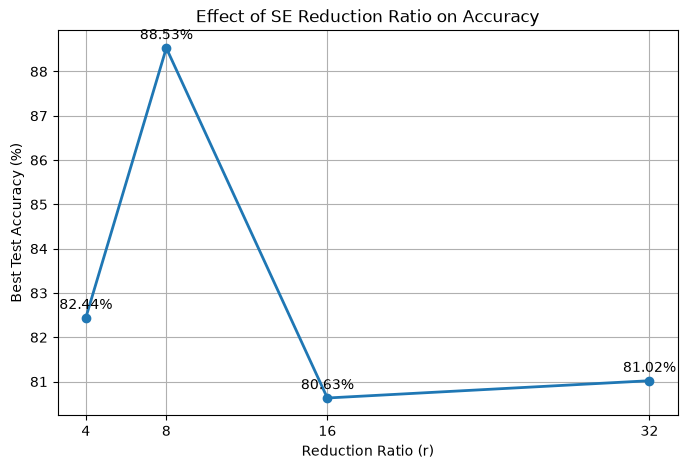

In [ ]:
import matplotlib.pyplot as plt

reduction_ratios = ablation_df["Reduction Ratio"]
accuracies = ablation_df["Best Test Accuracy (%)"]

plt.figure(figsize=(8, 5))

plt.plot(
    reduction_ratios,
    accuracies,
    marker="o",
    linewidth=2
)

for r, acc in zip(reduction_ratios, accuracies):
    plt.text(
        r,
        acc + 0.2,
        f"{acc:.2f}%",
        ha="center"
    )

plt.xlabel("Reduction Ratio (r)")
plt.ylabel("Best Test Accuracy (%)")
plt.title("Effect of SE Reduction Ratio on Accuracy")

plt.xticks([4, 8, 16, 32])
plt.grid()

plt.show()

SE channel attention visualization

In [ ]:

import os
import torch

# ==================== LOAD BEST r=16 MODEL ====================

best_model_path_r16 = os.path.join(
    checkpoint_dir_r16,
    "best_model.pth"
)

if not os.path.exists(best_model_path_r16):
    raise FileNotFoundError(
        f"Best r=16 model not found at:\n"
        f"{os.path.abspath(best_model_path_r16)}\n"
        "Run the r=16 training cell first and ensure a best model is saved."
    )

se_model_r16.load_state_dict(
    torch.load(
        best_model_path_r16,
        map_location=device,
        weights_only=True
    )
)

se_model_r16.eval()

print("Best r=16 model loaded successfully.")


# ==================== CAPTURE ATTENTION ====================

attention_weights = []

def capture_attention(module, inputs, output):
    attention_weights.append(output.detach().cpu())


# Hook on the SE block in the first residual block
hook = se_model_r16.layer1[0].se.register_forward_hook(
    capture_attention
)

try:
    # Fetch one batch
    images, labels = next(iter(test_loader))
    images = images.to(device)

    # Forward pass
    with torch.no_grad():
        outputs = se_model_r16(images)

finally:
    # Always remove hook, even if forward pass fails
    hook.remove()


# ==================== CHECK RESULTS ====================

print("Number of captured attention outputs:", len(attention_weights))

if attention_weights:
    print("Captured output shape:", attention_weights[0].shape)
    print("Model output shape:", outputs.shape)
else:
    print("No attention output was captured. Check the SE block location.")


Best r=16 model loaded successfully.
Number of captured attention outputs: 1
Captured output shape: torch.Size([128, 64, 32, 32])
Model output shape: torch.Size([128, 10])


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

Feature map shape: torch.Size([64, 32, 32])


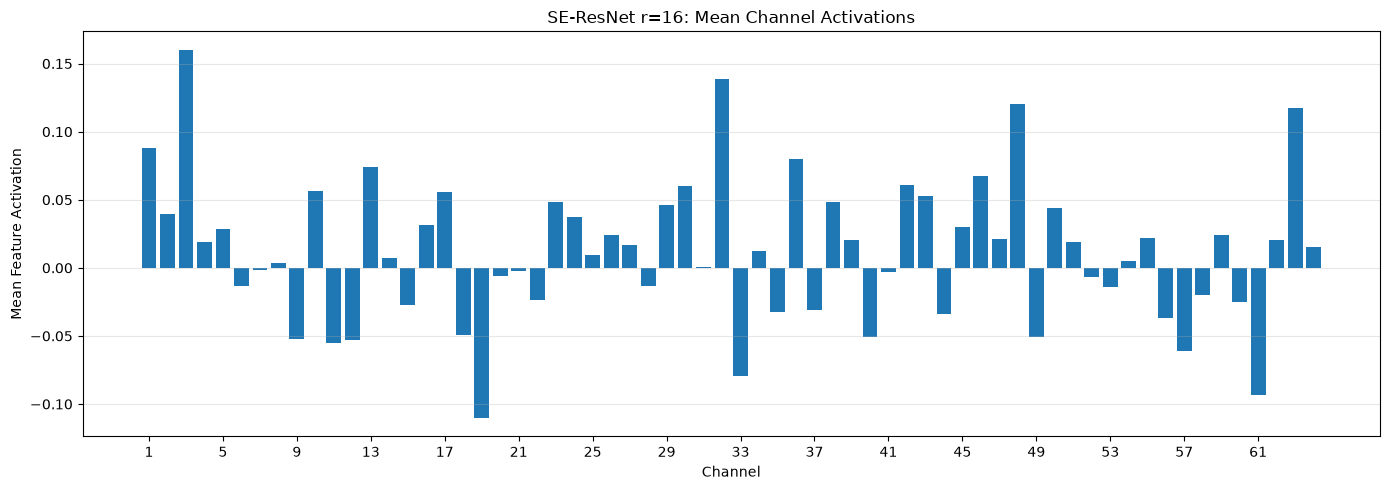

In [ ]:

import matplotlib.pyplot as plt
import torch

# Get the captured output for the first image
feature_maps = attention_weights[0][0]

# Expected shape: (channels, height, width)
print("Feature map shape:", feature_maps.shape)

# Average over height and width to get one value per channel
channel_values = feature_maps.mean(dim=(-2, -1))

# Convert to a 1D NumPy array
channel_values = channel_values.detach().cpu().numpy()

# Channel numbers
channels = range(1, len(channel_values) + 1)

plt.figure(figsize=(14, 5))
plt.bar(channels, channel_values)

plt.xlabel("Channel")
plt.ylabel("Mean Feature Activation")
plt.title("SE-ResNet r=16: Mean Channel Activations")
plt.xticks(range(1, len(channel_values) + 1, 4))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


Original feature map shape: torch.Size([64, 32, 32])
Channel values shape: (64,)

Top 10 Channels by Mean Feature Activation
Channel 3: 0.1602
Channel 32: 0.1387
Channel 48: 0.1204
Channel 63: 0.1178
Channel 1: 0.0882
Channel 36: 0.0803
Channel 13: 0.0743
Channel 46: 0.0676
Channel 42: 0.0605
Channel 30: 0.0598


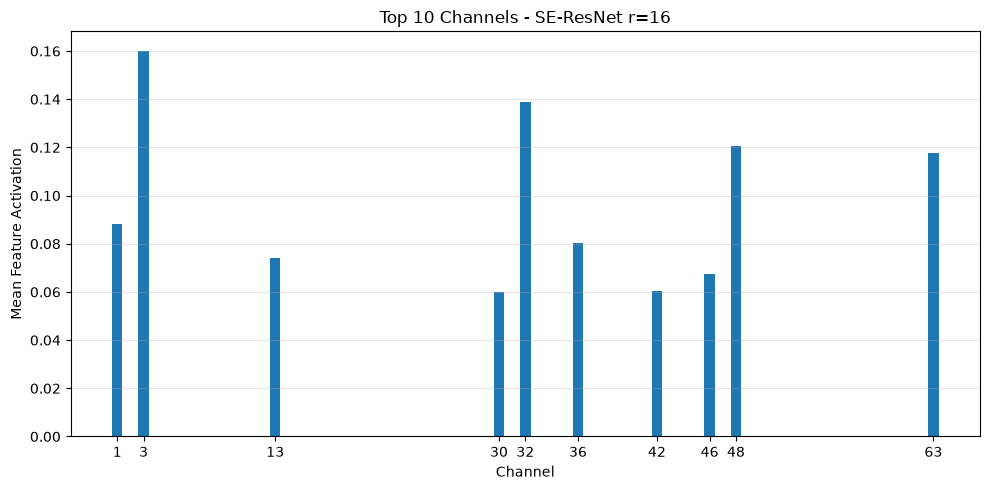

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# attention_weights[0][0] has shape (64, 32, 32)
feature_maps = attention_weights[0][0]

print("Original feature map shape:", feature_maps.shape)

# Average spatial dimensions to get one value per channel
attention = (
    feature_maps
    .mean(dim=(-2, -1))
    .detach()
    .cpu()
    .numpy()
)

print("Channel values shape:", attention.shape)

# Select top 10 channels
top_indices = np.argsort(attention)[-10:][::-1]

top_channels = top_indices + 1
top_weights = attention[top_indices]

print("\nTop 10 Channels by Mean Feature Activation")

for channel, weight in zip(top_channels, top_weights):
    print(f"Channel {channel}: {weight:.4f}")

# Plot top 10 channels
plt.figure(figsize=(10, 5))
plt.bar(top_channels, top_weights)

plt.xlabel("Channel")
plt.ylabel("Mean Feature Activation")
plt.title("Top 10 Channels - SE-ResNet r=16")
plt.xticks(top_channels)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


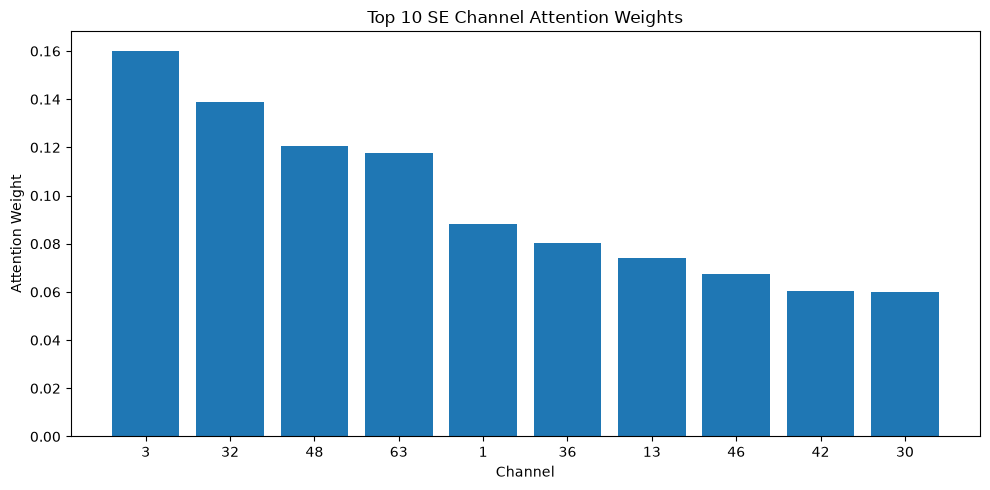

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    [str(c) for c in top_channels],
    top_weights
)

plt.xlabel("Channel")
plt.ylabel("Attention Weight")
plt.title("Top 10 SE Channel Attention Weights")

plt.tight_layout()
plt.show()

In [ ]:
# Final model results

best_ablation_index = ablation_df["Best Test Accuracy (%)"].idxmax()

best_ablation_r = int(
    ablation_df.loc[
        best_ablation_index,
        "Reduction Ratio"
    ]
)

best_ablation_accuracy = ablation_df.loc[
    best_ablation_index,
    "Best Test Accuracy (%)"
]

final_results = pd.DataFrame({
    "Model": [
        "Baseline ResNet",
        "SE-ResNet (r=16)",
        f"Best Ablation (r={best_ablation_r})"
    ],
    "Parameters": [
        total_params,
        se_total_params,
        ablation_df.loc[
            best_ablation_index,
            "Parameters"
        ]
    ],
    "Best Test Accuracy (%)": [
        best_test_acc,
        best_se_test_acc,
        best_ablation_accuracy
    ],
    "Best Epoch": [
        best_epoch,
        best_se_epoch,
        ablation_df.loc[
            best_ablation_index,
            "Best Epoch"
        ]
    ],
    "Training Time (minutes)": [
        total_time / 60,
        total_se_time / 60,
        ablation_df.loc[
            best_ablation_index,
            "Training Time (minutes)"
        ]
    ]
})

display(final_results)

,Model,Parameters,Best Test Accuracy (%),Best Epoch,Training Time (minutes)
0,Baseline ResNet,11173962,88.18,99,48.305940
1,SE-ResNet (r=16),11263042,88.53,66,72.517131
2,Best Ablation (r=8),11350202,88.53,34,22.679287


Accuracy improvement

In [ ]:
accuracy_gain = best_se_test_acc - best_test_acc

print(
    f"SE-ResNet accuracy gain over baseline: "
    f"{accuracy_gain:+.2f} percentage points"
)

print(
    f"Best ablation reduction ratio: r={best_ablation_r}"
)

print(
    f"Best ablation accuracy: "
    f"{best_ablation_accuracy:.2f}%"
)

SE-ResNet accuracy gain over baseline: +0.35 percentage points
Best ablation reduction ratio: r=8
Best ablation accuracy: 88.53%


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

# Store actual and predicted labels

all_labels = []
all_predictions = []

se_model_r16.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = se_model_r16(images)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_labels.extend(
            labels.numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)


# Classification report

print("Classification Report")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=[
            "Airplane",
            "Automobile",
            "Bird",
            "Cat",
            "Deer",
            "Dog",
            "Frog",
            "Horse",
            "Ship",
            "Truck"
        ]
    )
)


# Confusion matrix

cm = confusion_matrix(
    all_labels,
    all_predictions
)

print("Confusion Matrix:")
print(cm)

Classification Report
              precision    recall  f1-score   support

    Airplane       0.79      0.81      0.80      1000
  Automobile       0.83      0.93      0.88      1000
        Bird       0.71      0.78      0.75      1000
         Cat       0.74      0.51      0.61      1000
        Deer       0.84      0.75      0.79      1000
         Dog       0.70      0.81      0.75      1000
        Frog       0.88      0.82      0.85      1000
       Horse       0.86      0.87      0.86      1000
        Ship       0.90      0.86      0.88      1000
       Truck       0.82      0.92      0.87      1000

    accuracy                           0.81     10000
   macro avg       0.81      0.81      0.80     10000
weighted avg       0.81      0.81      0.80     10000

Confusion Matrix:
[[813  15  32   8   3   7   2   8  48  64]
 [  6 928   1   0   0   2   0   1   1  61]
 [ 70   7 781  17  36  33  30  13   9   4]
 [ 36  20  94 514  37 194  45  30  11  19]
 [ 34   5  66  28 751  35  23

Confusion Matrix visualization

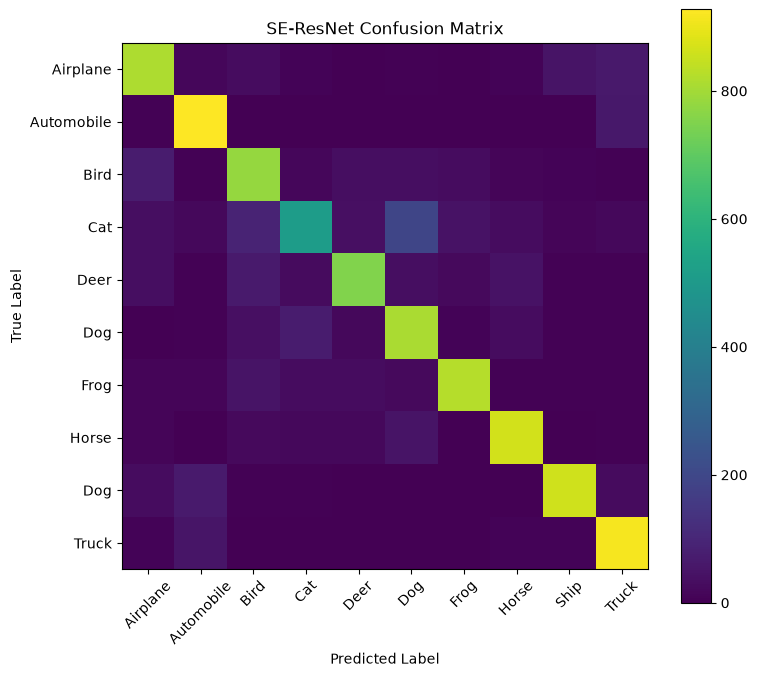

In [ ]:
plt.figure(figsize=(8, 7))

plt.imshow(cm)

plt.colorbar()

plt.xticks(
    range(10),
    [
        "Airplane",
        "Automobile",
        "Bird",
        "Cat",
        "Deer",
        "Dog",
        "Frog",
        "Horse",
        "Ship",
        "Truck"
    ],
    rotation=45
)

plt.yticks(
    range(10),
    [
        "Airplane",
        "Automobile",
        "Bird",
        "Cat",
        "Deer",
        "Dog",
        "Frog",
        "Horse",
        "Dog",
        "Truck"
    ]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("SE-ResNet Confusion Matrix")

plt.tight_layout()
plt.show()

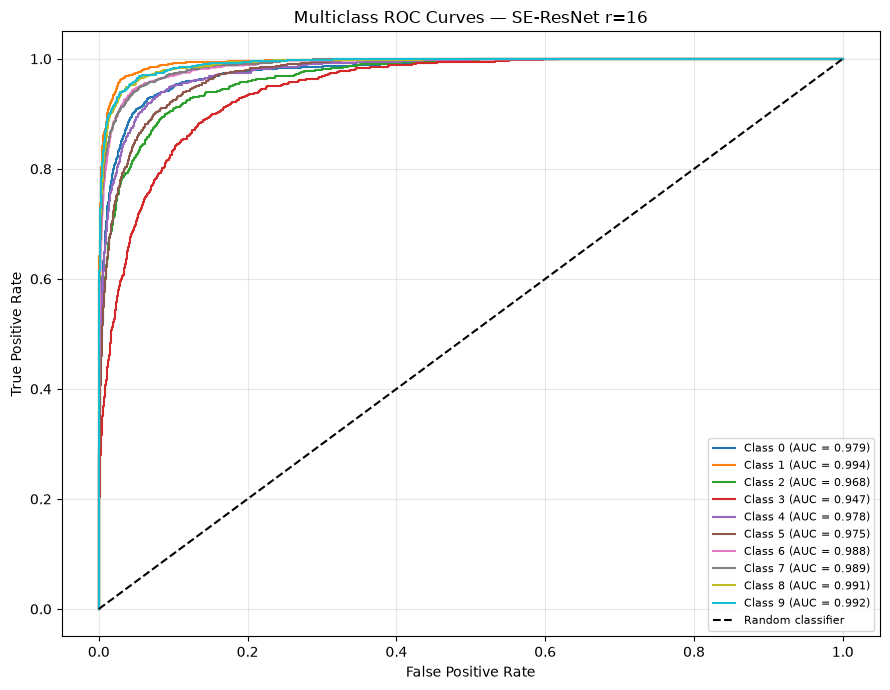

In [ ]:

import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

se_model_r16.eval()

all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        logits = se_model_r16(images)
        probs = torch.softmax(logits, dim=1)

        all_probs.append(probs.cpu().numpy())
        all_labels.append(labels.numpy())

y_true = np.concatenate(all_labels)
y_score = np.concatenate(all_probs)

# Convert labels to one-hot format for multiclass ROC
classes = np.arange(10)
y_true_bin = label_binarize(y_true, classes=classes)

plt.figure(figsize=(9, 7))

for i in range(10):
    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        y_score[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr, tpr,
        label=f"Class {i} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves — SE-ResNet r=16")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### ROC-AUC

In [ ]:
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize
import numpy as np
import torch

# Store true labels and predicted probabilities

all_labels_auc = []
all_probabilities = []

se_model_r16.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = se_model_r16(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        all_labels_auc.extend(
            labels.numpy()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

all_labels_auc = np.array(all_labels_auc)
all_probabilities = np.array(all_probabilities)


# Convert class labels into one-hot format

labels_one_hot = label_binarize(
    all_labels_auc,
    classes=np.arange(10)
)


# Calculate multiclass ROC-AUC

roc_auc = roc_auc_score(
    labels_one_hot,
    all_probabilities,
    multi_class="ovr",
    average="macro"
)

print(
    f"Macro One-vs-Rest ROC-AUC: {roc_auc:.4f}"
)

Macro One-vs-Rest ROC-AUC: 0.9801


In [ ]:
class_names = [
    "Airplane",
    "Automobile",
    "Bird",
    "Cat",
    "Deer",
    "Dog",
    "Frog",
    "Horse",
    "Ship",
    "Truck"
]

print("Class-wise ROC-AUC")

for i, class_name in enumerate(class_names):

    class_auc = roc_auc_score(
        labels_one_hot[:, i],
        all_probabilities[:, i]
    )

    print(
        f"{class_name}: {class_auc:.4f}"
    )

Class-wise ROC-AUC
Airplane: 0.9786
Automobile: 0.9940
Bird: 0.9676
Cat: 0.9469
Deer: 0.9783
Dog: 0.9746
Frog: 0.9883
Horse: 0.9893
Ship: 0.9915
Truck: 0.9921


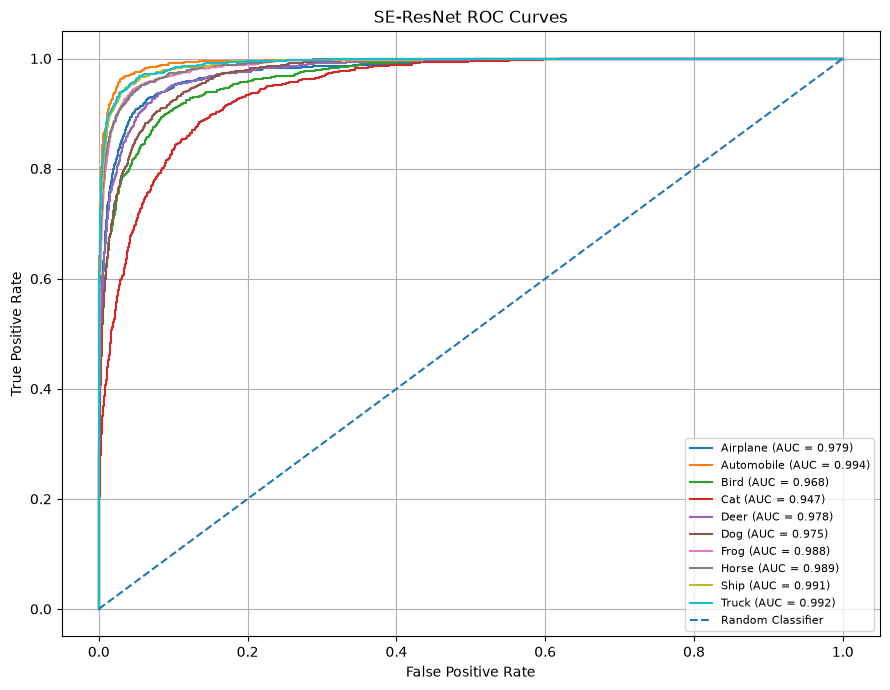

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

for i, class_name in enumerate(class_names):

    fpr, tpr, _ = roc_curve(
        labels_one_hot[:, i],
        all_probabilities[:, i]
    )

    class_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {class_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("SE-ResNet ROC Curves")

plt.legend(
    loc="lower right",
    fontsize=8
)

plt.grid()
plt.tight_layout()

plt.show()

In [ ]:
# Final results table

final_results.to_csv(
    "SE_ResNet_Final_Results.csv",
    index=False
)

print("Final results saved as SE_ResNet_Final_Results.csv")

Final results saved as SE_ResNet_Final_Results.csv


In [ ]:
# Ablation study results

ablation_df.to_csv(
    "SE_ResNet_Ablation_Results.csv",
    index=False
)

print("Ablation results saved as SE_ResNet_Ablation_Results.csv")

Ablation results saved as SE_ResNet_Ablation_Results.csv


In [ ]:

import torch
import pandas as pd
from sklearn.metrics import classification_report

# Ensure model is in evaluation mode
se_model_r16.eval()

all_labels = []
all_predictions = []

# Regenerate labels and predictions from the SAME test_loader
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = se_model_r16(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy().tolist())
        all_predictions.extend(predictions.cpu().numpy().tolist())

# Validate sample counts
print("Number of true labels:", len(all_labels))
print("Number of predictions:", len(all_predictions))

assert len(all_labels) == len(all_predictions), (
    "Mismatch between labels and predictions."
)

# Generate classification report
report = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

classification_df = pd.DataFrame(report).transpose()

# Save report
classification_df.to_csv(
    "SE_ResNet_Classification_Report.csv",
    index=True
)

print("Classification report saved.")
display(classification_df)


Number of true labels: 10000
Number of predictions: 10000
Classification report saved.


,precision,recall,f1-score,support
Airplane,0.791626,0.8130,0.802171,1000.0000
Automobile,0.833783,0.9280,0.878372,1000.0000
Bird,0.714547,0.7810,0.746297,1000.0000
Cat,0.740634,0.5140,0.606848,1000.0000
Deer,0.836303,0.7510,0.791359,1000.0000
Dog,0.699482,0.8100,0.750695,1000.0000
Frog,0.883047,0.8230,0.851967,1000.0000
Horse,0.856578,0.8660,0.861263,1000.0000
Ship,0.897810,0.8610,0.879020,1000.0000
Truck,0.821525,0.9160,0.866194,1000.0000


In [ ]:
# Create master comparison table

best_ablation_index = ablation_df["Best Test Accuracy (%)"].idxmax()

master_results = pd.DataFrame({
    "Model": [
        "Baseline ResNet",
        "SE-ResNet r=4",
        "SE-ResNet r=8",
        "SE-ResNet r=16",
        "SE-ResNet r=32"
    ],
    "Parameters": [
        total_params,
        r4_params,
        r8_params,
        r16_params,
        r32_params
    ],
    "Best Test Accuracy (%)": [
        best_test_acc,
        best_r4_test_acc,
        best_r8_test_acc,
        best_r16_test_acc,
        best_r32_test_acc
    ],
    "Best Epoch": [
        best_epoch,
        best_r4_epoch,
        best_r8_epoch,
        best_r16_epoch,
        best_r32_epoch
    ],
    "Training Time (minutes)": [
        total_time / 60,
        total_time_r4 / 60,
        total_time_r8 / 60,
        total_time_r16 / 60,
        total_time_r32 / 60
    ]
})

display(master_results)

,Model,Parameters,Best Test Accuracy (%),Best Epoch,Training Time (minutes)
0,Baseline ResNet,11173962,88.18,99,48.305940
1,SE-ResNet r=4,11524522,82.44,9,9.747792
2,SE-ResNet r=8,11350202,88.53,34,22.679287
3,SE-ResNet r=16,11263042,80.63,20,15.679525
4,SE-ResNet r=32,11219462,81.02,21,16.169340


In [ ]:
best_model_index = master_results["Best Test Accuracy (%)"].idxmax()

print(
    "Best Model:",
    master_results.loc[best_model_index, "Model"]
)

print(
    "Best Accuracy:",
    f"{master_results.loc[best_model_index, 'Best Test Accuracy (%)']:.2f}%"
)

print(
    "Parameters:",
    int(master_results.loc[best_model_index, "Parameters"])
)

print(
    "Best Epoch:",
    int(master_results.loc[best_model_index, "Best Epoch"])
)

Best Model: SE-ResNet r=8
Best Accuracy: 88.53%
Parameters: 11350202
Best Epoch: 34


In [ ]:
master_results.to_csv(
    "SE_ResNet_Master_Results.csv",
    index=False
)

print("Master results saved.")

Master results saved.


In [ ]:
# Select the best performing model

best_model_row = master_results.loc[
    master_results["Best Test Accuracy (%)"].idxmax()
]

print("Best Model:", best_model_row["Model"])
print(
    "Best Test Accuracy:",
    f"{best_model_row['Best Test Accuracy (%)']:.2f}%"
)
print(
    "Parameters:",
    int(best_model_row["Parameters"])
)
print(
    "Best Epoch:",
    int(best_model_row["Best Epoch"])
)
print(
    "Training Time:",
    f"{best_model_row['Training Time (minutes)']:.2f} minutes"
)

Best Model: SE-ResNet r=8
Best Test Accuracy: 88.53%
Parameters: 11350202
Best Epoch: 34
Training Time: 22.68 minutes


In [ ]:
# Create final performance summary

final_summary = {
    "Baseline ResNet Accuracy (%)": best_test_acc,
    "SE-ResNet r=16 Accuracy (%)": best_se_test_acc,
    "SE-ResNet r=16 ROC-AUC": roc_auc,
    "Best Ablation Ratio": best_r,
    "Best Ablation Accuracy (%)": best_r_accuracy,
    "Baseline Parameters": total_params,
    "SE-ResNet r=16 Parameters": se_total_params
}

for key, value in final_summary.items():
    print(
        f"{key}: {value}"
    )

Baseline ResNet Accuracy (%): 88.18
SE-ResNet r=16 Accuracy (%): 88.53
SE-ResNet r=16 ROC-AUC: 0.9801202388888888
Best Ablation Ratio: 8
Best Ablation Accuracy (%): 88.53
Baseline Parameters: 11173962
SE-ResNet r=16 Parameters: 11263042
